# Breast Cancer Diagnosis (Wisconsin)

**Course:** SE309 AI and Data Science for Innovation in Health Science · Fall 2026–27
**Topic code:** SE309-03 · **Working as:** Individual
**Repository:** https://github.com/TalhaTufanN/se309-breast-cancer-diagnosis

| Name | Student no. | GitHub username |
|---|---|---|
| Talha Tufan | 220201035 | @TalhaTufanN |

> Educational project only. The models here are **not** a diagnostic tool and must not be used for real patients.

## 1. Problem

A fine needle aspirate (FNA) takes a small sample of cells from a breast mass. A pathologist looks at the cells under a microscope and decides whether the mass is benign or malignant. The Wisconsin data describes each sample with 30 measurements of the cell nuclei computed from a digitised image.

This project asks: **how well can simple machine-learning models separate benign from malignant tumours using these measurements, and what does it cost when the model misses a malignant tumour (a false negative)?**

The finished project explores the strongly correlated features, compares at least two models with a majority-class baseline, reports confusion matrices with sensitivity and specificity, and discusses the cost of false negatives. As an extension it tests feature selection and a single-feature baseline. The result is meant for learning, not for clinical use.

## 2. Data

**Breast Cancer Wisconsin (Diagnostic)**, W. H. Wolberg, W. N. Street and O. L. Mangasarian, University of Wisconsin, 1995.
Source: [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic) · licence: CC BY 4.0.
Size: 569 samples × 30 numeric features + 1 label (357 benign, 212 malignant).

The data ships with scikit-learn, so it is loaded below with `load_breast_cancer()` and nothing has to be downloaded. The same data is saved as `data/wdbc.csv` and `data/wdbc.arff` (for Weka) by `data/make_data.py`.

The 30 features are 10 nucleus properties (radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, fractal dimension), each given three times: the **mean** over all nuclei in the image, the **standard error**, and the **worst** (mean of the three largest values).

### Data note
*Checked against the UCI description and Wolberg, Street & Mangasarian (1997). "Not stated" means that these sources do not say it.*

1. **Who** is in the data — and who could never have been? A consecutive series of 569 patients with a breast mass that had a fine needle aspirate (FNA), at the University of Wisconsin. In the 1997 paper, most samples came from palpable masses and only solid masses that yielded epithelial cells were analysed. People whose masses were never aspirated and patients at other institutions could not be included. The file records no age, sex or ethnicity, so subgroup analysis is impossible.
2. **Why** was it collected? FNA is a diagnostic procedure. The measurements were used for research, to develop and train Xcyt, a computer-aided diagnosis system.
3. **When and where?** University of Wisconsin, Madison, USA. The training on these 569 samples was done by 1994 and the data was donated to UCI in November 1995. The exact collection years are not stated.
4. **What exactly is the label**, and who decided it? Benign or malignant, described only as "established diagnoses". In the later test series of the same study, all cancers and some benign masses were confirmed by histology, and the other benign masses by one year of follow-up. The sources do not state how the 569 training labels were confirmed.
5. **What is missing**, how much, and by which mechanism? No values are missing in the file, so MCAR/MAR/MNAR does not apply to the columns. Whole samples may be absent instead: in the later series, samples with too few cells could not be analysed.
6. **Which values are impossible?** No negative values. 13 benign samples have 0 in all concavity and concave-points columns; this means a smooth nucleus outline, which is plausible, so the values are kept (Section 4.3).
7. **When** does each column become available (risk of leakage)? All features come from the FNA image, and no column directly contains the outcome. However, a human operator selects the image area and outlines the nuclei, and the sources do not state whether the operator knew the diagnosis.
8. **Who consented**, and to what? Not stated. The scikit-learn version of the data contains no names or patient identifiers.


## 3. Setup

*Install anything that is not in Colab by default, import the libraries, and fix random seeds so results can be reproduced.*

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.datasets import load_breast_cancer

SEED = 42
np.random.seed(SEED)

# Figures are saved to the images/ folder of the repository
IMG = Path("../images") if Path("../images").is_dir() else Path("images")
IMG.mkdir(exist_ok=True)

In [2]:
# Load the data (same columns and labels as data/wdbc.csv)
bunch = load_breast_cancer(as_frame=True)
df = bunch.frame.copy()

# In scikit-learn 0 = malignant and 1 = benign; we use readable labels instead.
df["diagnosis"] = df["target"].map({0: "malignant", 1: "benign"})
df = df.drop(columns="target")
df.columns = [c.replace(" ", "_") for c in df.columns]

print(df.shape)
df.head()

(569, 31)


,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,mean_compactness,mean_concavity,mean_concave_points,mean_symmetry,mean_fractal_dimension,...,worst_texture,worst_perimeter,worst_area,worst_smoothness,worst_compactness,worst_concavity,worst_concave_points,worst_symmetry,worst_fractal_dimension,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,malignant


## 4. Exploration

*Five-number summaries, distributions by class, impossible values, missingness per column, a few well-labelled plots (Week 3). Comment on what you see under each plot.*

### 4.1 Class balance

How many tumours are benign and how many malignant? If one class is much larger, accuracy alone can be misleading.

diagnosis
benign       357
malignant    212
Name: count, dtype: int64
diagnosis
benign       0.627
malignant    0.373
Name: count, dtype: float64


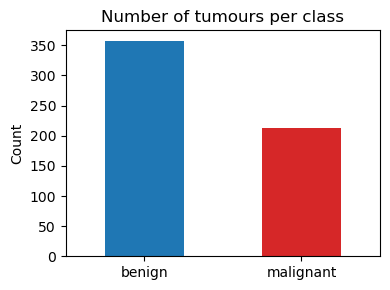

In [3]:
counts = df["diagnosis"].value_counts()
print(counts)
print((counts / len(df)).round(3))

fig, ax = plt.subplots(figsize=(4, 3))
counts.plot.bar(ax=ax, color=["tab:blue", "tab:red"])
ax.set_title("Number of tumours per class")
ax.set_xlabel("")
ax.set_ylabel("Count")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig(IMG / "class_balance.png", dpi=150)
plt.show()

63% of the tumours are benign and 37% malignant. The classes are not strongly imbalanced, but a model that always says "benign" would already reach about 63% accuracy. This is the **majority-class baseline** that every model must beat (Section 6).

### 4.2 Five-number summaries, missing values and duplicates

In [4]:
features = [c for c in df.columns if c != "diagnosis"]

print("Missing values in total:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
df[features].describe().T.round(3)

Missing values in total: 0
Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
mean_radius,569.0,14.127,3.524,6.981,11.700,13.370,15.780,28.110
mean_texture,569.0,19.290,4.301,9.710,16.170,18.840,21.800,39.280
mean_perimeter,569.0,91.969,24.299,43.790,75.170,86.240,104.100,188.500
mean_area,569.0,654.889,351.914,143.500,420.300,551.100,782.700,2501.000
mean_smoothness,569.0,0.096,0.014,0.053,0.086,0.096,0.105,0.163
mean_compactness,569.0,0.104,0.053,0.019,0.065,0.093,0.130,0.345
mean_concavity,569.0,0.089,0.080,0.000,0.030,0.062,0.131,0.427
mean_concave_points,569.0,0.049,0.039,0.000,0.020,0.034,0.074,0.201
mean_symmetry,569.0,0.181,0.027,0.106,0.162,0.179,0.196,0.304
mean_fractal_dimension,569.0,0.063,0.007,0.050,0.058,0.062,0.066,0.097


There are no missing values and no duplicate rows. The features are on very different scales: `mean_area` goes from about 144 to 2501, while `mean_smoothness` stays between 0.05 and 0.16. Models that use distances (e.g. k-NN, SVM) or regularisation (logistic regression) therefore need **scaling**, which is done in Section 5 on the training set only.

### 4.3 Impossible or suspicious values

All features are sizes or shape measures, so negative values would be impossible. Zeros need a closer look.

In [5]:
print("Negative values:", (df[features] < 0).sum().sum())

zeros = (df[features] == 0).sum()
print(zeros[zeros > 0])

zero_rows = df[df["mean_concavity"] == 0]
print()
print("Rows with mean_concavity = 0:", len(zero_rows))
print(zero_rows["diagnosis"].value_counts())

Negative values: 0
mean_concavity          13
mean_concave_points     13
concavity_error         13
concave_points_error    13
worst_concavity         13
worst_concave_points    13
dtype: int64

Rows with mean_concavity = 0: 13
diagnosis
benign    13
Name: count, dtype: int64


There are no negative values. 13 samples have **0 in all six concavity and concave-points columns**, and all 13 are benign. Concavity measures how deep the indentations in the nucleus outline are, so 0 means a smooth outline with no indentations. This is plausible for benign cells, so these values are treated as real and **kept**. The decision is noted in the data note (Section 2, question 6).

### 4.4 Distributions by class

The ten "mean" features, with benign and malignant tumours drawn separately. A feature is useful for classification when the two histograms overlap little.

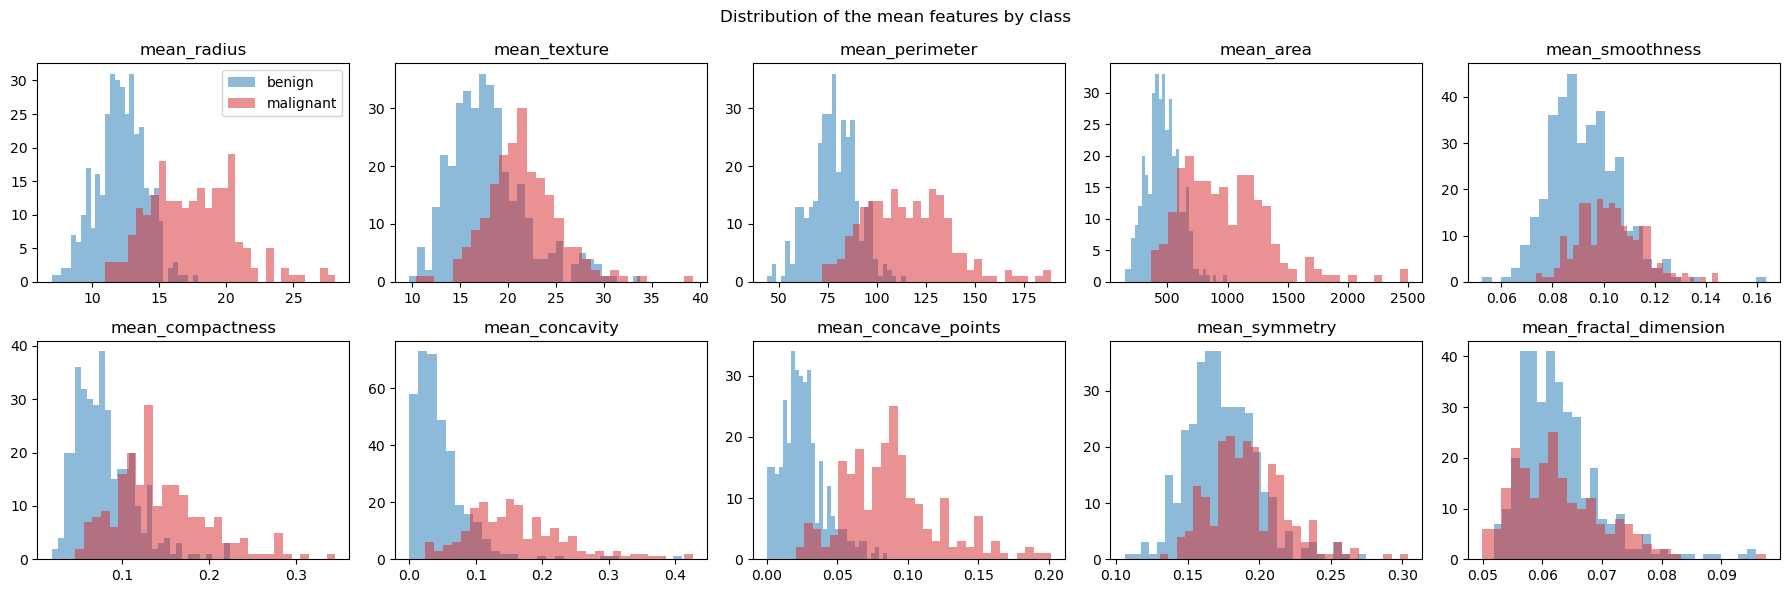

In [6]:
mean_features = [c for c in features if c.startswith("mean_")]

fig, axes = plt.subplots(2, 5, figsize=(18, 6))
for ax, col in zip(axes.ravel(), mean_features):
    for label, color in [("benign", "tab:blue"), ("malignant", "tab:red")]:
        ax.hist(df.loc[df["diagnosis"] == label, col], bins=30, alpha=0.5, color=color, label=label)
    ax.set_title(col)
axes[0, 0].legend()
fig.suptitle("Distribution of the mean features by class")
plt.tight_layout()
plt.savefig(IMG / "distributions_by_class.png", dpi=150)
plt.show()

In [7]:
# Medians per class: a quick numeric version of the plots above
df.groupby("diagnosis")[mean_features].median().T.round(3)

diagnosis,benign,malignant
mean_radius,12.200,17.325
mean_texture,17.390,21.460
mean_perimeter,78.180,114.200
mean_area,458.400,932.000
mean_smoothness,0.091,0.102
mean_compactness,0.075,0.132
mean_concavity,0.037,0.151
mean_concave_points,0.023,0.086
mean_symmetry,0.171,0.190
mean_fractal_dimension,0.062,0.062


- **Size features** (`mean_radius`, `mean_perimeter`, `mean_area`) and **concavity features** (`mean_concavity`, `mean_concave_points`) separate the classes best: malignant nuclei are larger and have deeper indentations. For example, the median `mean_area` is about 458 for benign and 932 for malignant tumours.
- `mean_texture`, `mean_compactness` and `mean_smoothness` also differ, but the histograms overlap more.
- `mean_symmetry` differs only slightly, and `mean_fractal_dimension` hardly at all (the medians are almost equal), so on their own they carry little information.
- Several features are right-skewed (a long tail of large values, e.g. `mean_area`), mostly because of the malignant tumours.

Because size features such as radius, perimeter and area measure almost the same thing, they are expected to be strongly correlated. This is examined in Section 4.5.

### 4.5 Correlated features

The 30 features describe the same nuclei in different ways, so many of them should carry overlapping information. The heatmap shows the Pearson correlation between every pair of features.

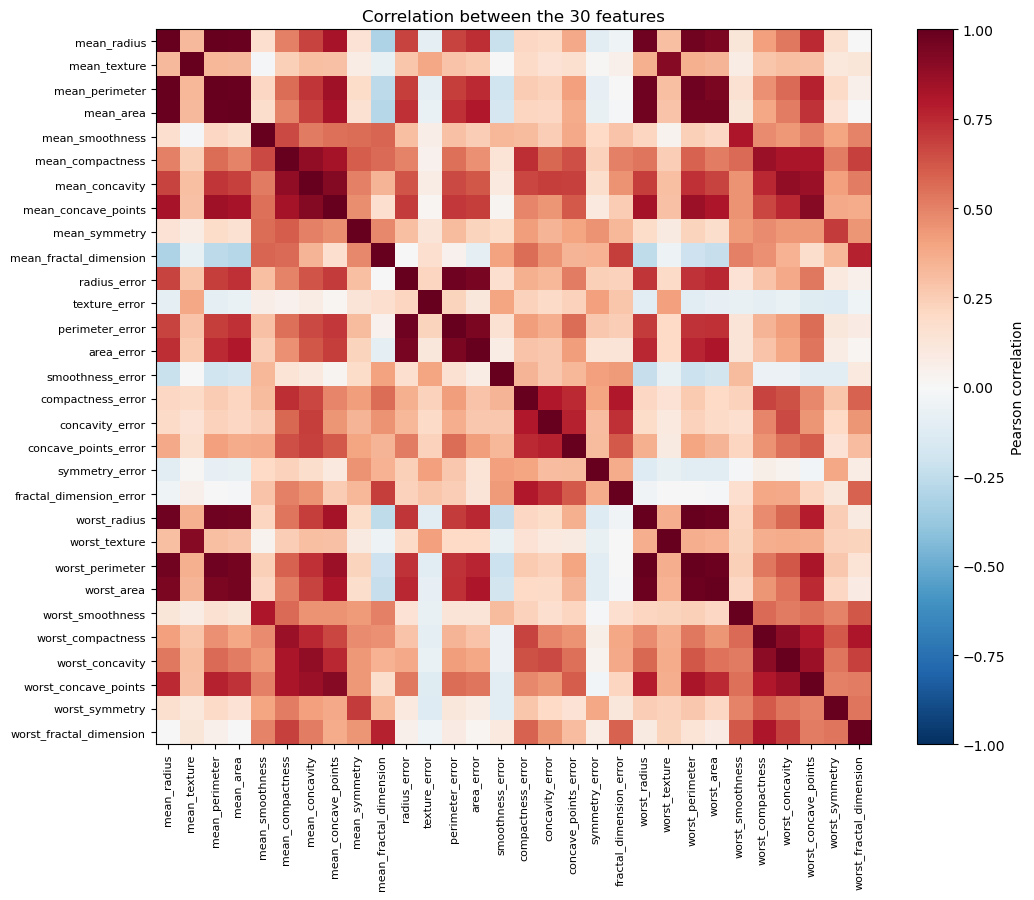

In [8]:
corr = df[features].corr()

fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(features)), features, rotation=90, fontsize=8)
ax.set_yticks(range(len(features)), features, fontsize=8)
fig.colorbar(im, ax=ax, label="Pearson correlation")
ax.set_title("Correlation between the 30 features")
plt.tight_layout()
plt.savefig(IMG / "correlation_heatmap.png", dpi=150)
plt.show()

In [9]:
# Every pair once: keep only the part of the matrix above the diagonal
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
pairs = upper.abs().sort_values(ascending=False)

print("Feature pairs in total:", len(pairs))
print("Pairs with |r| > 0.9:", (pairs > 0.9).sum())
print("Pairs with |r| > 0.8:", (pairs > 0.8).sum())
pairs.head(10).round(3).to_frame("|r|")

Feature pairs in total: 435
Pairs with |r| > 0.9: 21
Pairs with |r| > 0.8: 44


,,|r|
mean_radius,mean_perimeter,0.998
worst_radius,worst_perimeter,0.994
mean_radius,mean_area,0.987
mean_perimeter,mean_area,0.987
worst_radius,worst_area,0.984
worst_perimeter,worst_area,0.978
radius_error,perimeter_error,0.973
mean_perimeter,worst_perimeter,0.970
mean_radius,worst_radius,0.970
mean_perimeter,worst_radius,0.969


The redundancy is strong: 21 of the 435 pairs have |r| > 0.9. Radius, perimeter and area are almost the same information, because for a roughly round nucleus perimeter ≈ 2πr and area ≈ πr². For example, `mean_radius` and `mean_perimeter` have r = 0.998. The "mean" and "worst" versions of a feature are also strongly related (`mean_radius` and `worst_radius`: r = 0.97).

**Why this matters for the models:**
- It usually does not harm prediction, but it makes the **interpretation** unreliable. In logistic regression, the weight can be shared between correlated features in many ways, so individual coefficients can be unstable and can even change sign. Regularisation reduces this problem but does not remove it.
- Tree-based models can use either of two correlated features, so the importance may be split between them and each may look less important than it really is.
- Naive Bayes assumes the features are independent given the class. That assumption is clearly false here.
- Removing redundant features may give a simpler model with similar performance. This is tested in the extension (feature selection).

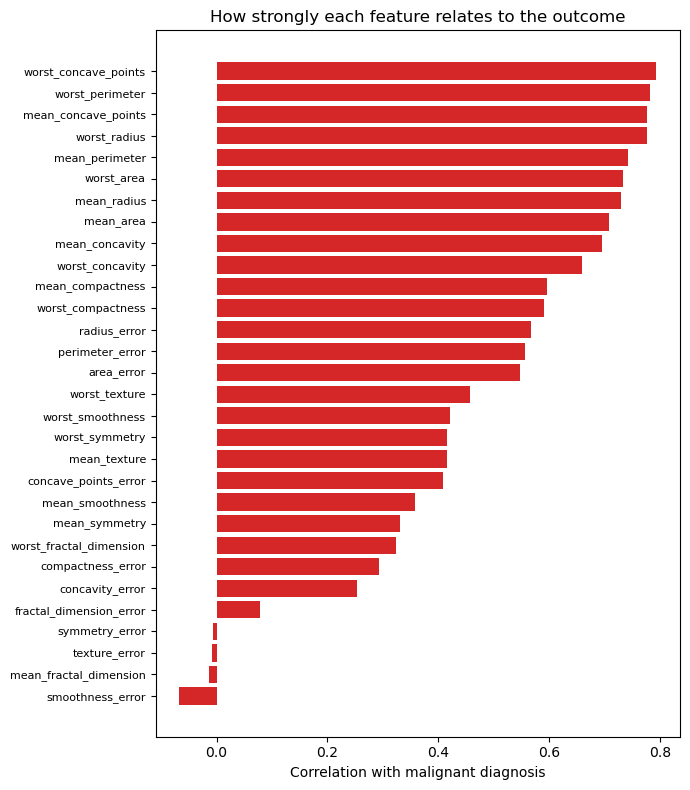

worst_concave_points    0.794
worst_perimeter         0.783
mean_concave_points     0.777
worst_radius            0.776
mean_perimeter          0.743
dtype: float64

In [10]:
# Correlation of each feature with the outcome (malignant = 1)
is_malignant = (df["diagnosis"] == "malignant").astype(int)
with_outcome = df[features].corrwith(is_malignant).sort_values()

fig, ax = plt.subplots(figsize=(7, 8))
ax.barh(with_outcome.index, with_outcome.values, color="tab:red")
ax.set_xlabel("Correlation with malignant diagnosis")
ax.set_title("How strongly each feature relates to the outcome")
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.savefig(IMG / "correlation_with_outcome.png", dpi=150)
plt.show()

with_outcome.sort_values(ascending=False).head(5).round(3)

The strongest relationships are with `worst_concave_points` (r = 0.79), `worst_perimeter` (0.78), `mean_concave_points` (0.78) and `worst_radius` (0.78). `smoothness_error`, `mean_fractal_dimension`, `texture_error` and `symmetry_error` are almost unrelated to the outcome when taken alone.

This fits the original study, which reached its best separation with only three features: worst area, worst smoothness and mean texture (Wolberg et al., 1997). Note that worst smoothness and mean texture are not at the very top of this chart: a good *combination* of features is not the same as the features that are individually strongest.

This chart uses all the data, so it is only a description. **Feature selection must not be based on it**, because that would let the test set influence the model (leakage). In the extension, features are selected using the training data only.

## 5. Preparation

*Follow the Week 4 order: (1) domain rules that use no statistics (e.g. impossible 0 → NaN); (2) **split first** (stratified, fixed seed); (3) learn every statistic — medians, min/max, mean/SD — on the training set only; (4) apply the same numbers to the test set. Explain each choice in one sentence.*

In [11]:
# from sklearn.model_selection import train_test_split
# train, test = train_test_split(df, test_size=0.25, stratify=df["<label>"], random_state=SEED)

## 6. Methods

*Which models or analyses, and why. Always include a simple **baseline** (e.g. ZeroR / majority class). If you also used Weka, give the exact classifier, filters and test option, and save the result buffer in `weka/`.*

In [12]:
# Model training

## 7. Results

*Results on the test set (or cross-validation) with suitable metrics — not only accuracy. Compare with the baseline. Where relevant, report results for subgroups (e.g. sex, age band).*

In [13]:
# Evaluation

## 8. Limitations and possible harms

*Which patients may the result not apply to? What could go wrong if someone used it in practice? What would you need to do before any real use?*

## 9. Contributions

*Fill in one row per member. This section must be consistent with the GitHub commit history and with the Contributions section of the report. Update it for the interim report (Week 10) and again for the final.*

| Member | GitHub username | Responsibilities | Notebook sections / files | Approx. share of work |
|---|---|---|---|---|
| <Full name> | @<username> | *e.g. data loading, cleaning* | *e.g. §2, §5, `src/clean.py`* | *e.g. 35%* |
| <Full name> | @<username> |  |  |  |

**What each member did, in their own words (2–4 sentences each):**

- **<Name>:** …
- **<Name>:** …

**Interim (Week 10) → Final:** *what changed in the division of work after the interim report, if anything.*

## 10. External code, libraries and AI tools

| What | Used for | Where |
|---|---|---|
| scikit-learn | loading the data | §3 |
| NumPy, pandas, Matplotlib | data handling and plots | §3–§4 |
| Claude (AI assistant) | drafting code and text, checking the data note against the sources, explaining methods | §1–§4, §10–§11, README |

## 11. References

1. Wolberg, W., Mangasarian, O., Street, N., & Street, W. (1993). *Breast Cancer Wisconsin (Diagnostic)*. UCI Machine Learning Repository. https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic
2. Wolberg, W. H., Street, W. N., & Mangasarian, O. L. (1997). Computerized diagnosis of breast fine-needle aspirates. *The Breast Journal*, 3(2), 77–80.
3. Wolberg, W. H., Street, W. N., & Mangasarian, O. L. (1994). Machine learning techniques to diagnose breast cancer from image-processed nuclear features of fine needle aspirates. *Cancer Letters*, 77(2), 163–171. https://doi.org/10.1016/0304-3835(94)90099-X
4. Street, W. N., Wolberg, W. H., & Mangasarian, O. L. (1993). Nuclear feature extraction for breast tumor diagnosis. *IS&T/SPIE International Symposium on Electronic Imaging*, 1905, 861–870.
5. scikit-learn documentation: https://scikit-learn.org/stable/

---
*Before submitting: Runtime → Restart and run all · no errors · every `<...>` replaced · notebook saved to the repository · same version uploaded to STIX.*